In [50]:
import torch
import torch.nn as nn
import torchvision
import torchvision.datasets as datasets
import random
import torch.nn.functional as F
import torchvision.transforms as transforms
from torchvision.transforms import v2
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from torch.utils.data import random_split
    
import numpy as np 
import matplotlib.pyplot as plt 

import itertools
import pandas as pd
import time
import math

## Pre-processing

**Define set seed function and configure our device**

In [23]:
# Hardware device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed = 67):
    """Seed every random number generator we use (67 = our group number, as in Task 1)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Using device: cuda


**Load data: train, validation and test**

In [42]:
# Load clock data
clock_images = np.load("data/A1_data_75/images.npy") # Shape: (18000, 75, 75), 18000 frayscale images of size 75 x 75 
clock_labels = np.load("data/A1_data_75/labels.npy") # Shape: (18000, 2): 18000 labels of hour and minute pairs

# Convert data to tensors: (number of images, channels, height, width) format
x = torch.from_numpy(clock_images).float().unsqueeze(1) # Grayscale so channel = 1

# Scale the pixels 
if x.max().item() > 1.0:                           
    x = x / 255.0 # Convert range from [0, 255] to [0, 1]

# Convert labels as tensor to long format
y = torch.from_numpy(clock_labels).long()

# Combine images and labels into a tensor dataset
clock_all = TensorDataset(x, y) 

# Define sizes of the 80/10/10 split for the train/validate/test set 
n = len(clock_all)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

# Split the data 
clock_train, clock_validation, clock_test = random_split(
    clock_all,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(67)
)


**Standardize the data**

The data is standardised with the mean and std of only the training images
Only training data cause the validation/test data should remain unseen (no leakage)

In [41]:
train_idx = clock_train.indices
mean, std = x[train_idx].mean(), x[train_idx].std() 
x.sub_(mean).div_(std) 
print(f"train mean/std used: {mean:.4f} / {std:.4f}")

train mean/std used: -0.0000 / 1.0000


**Visualise**

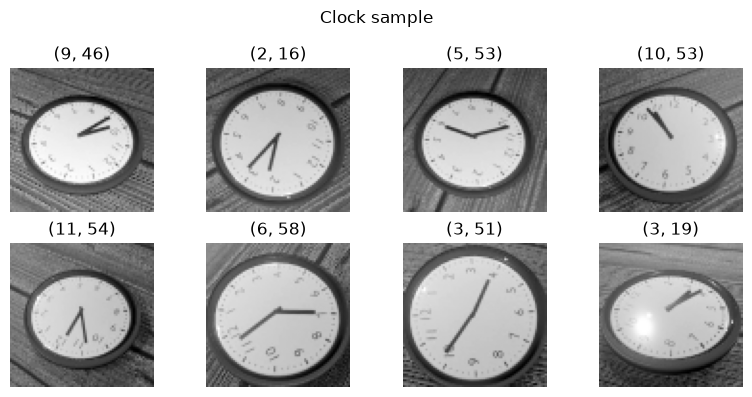

In [44]:
idxs = torch.randperm(len(x))[:8] # Indexes of random images

fig, ax = plt.subplots(2, 4, figsize=(8, 4))

for i, j in zip(idxs, ax.flat):
    hour, minute = y[i].tolist()
    j.imshow(x[i, 0], cmap = "gray")
    j.axis("off")
    j.set_title(f"({hour}, {minute})")

plt.suptitle("Clock sample")
plt.tight_layout()
plt.savefig("figures/visualise_clocks.png", dpi = 300)
plt.show()

**Creating the dataloaders**

Shuffling is set to true for the training set again to make sure that the batches are random between epochs. We don't need to shuffle for the validation and test set since we are only using those to evaluate the model. The order of images doesn't affect the overall result

We take the same batch size of Task 1 (64) to account for the fact that the images are much larger compared to what we had in task 1 (150x150, as apposed to 28x28) which requires more memory per batch. WIth 14,400 training images, this amounts to 225 updates per epoch

In [ ]:
batch_size = 64

# Create the DataLoaders
clock_train_loader = DataLoader(clock_train, batch_size = batch_size, shuffle = True)
clock_validation_loader = DataLoader(clock_validation, batch_size = batch_size, shuffle = False)
clock_test_loader = DataLoader(clock_test, batch_size = batch_size, shuffle = False)

In [46]:
print(f"Number of batches in the training DataLoader: {len(clock_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(clock_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(clock_test_loader)} \n")

images, labels = next(iter(clock_train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 225
Number of batches in the validation DataLoader: 29
Number of batches in the test DataLoader: 29 

Image batch shape: torch.Size([64, 1, 75, 75])
Label batch shape: torch.Size([64, 2])
Image data type: torch.float32
Pixel range: -2.3657608032226562 1.8514466285705566


## Evaluation metric: common-sense error

In [ ]:
def time_in_minutes(labels):
    """ 
    Convert the original (hour, minute) labels into minutes as hour 12 and hour 0 are the same
    Formula: t = (hour % 12) * 60 + minute 

    Examples
        (0, 0) -> 0
        (6, 0) -> 360
        (12, 0) -> 0

    Output: integer in [0, 719] 
    """
    time_minutes = (labels[:, 0] % 12) * 60 + labels[:, 1]
    return time_minutes

def common_sense_error(pred_minutes, true_minutes):
    """
    Absolute time difference between predicted and true time, taking into account the 12-hour wrap-around
    """

    # Calculate the difference between two time points in minutes
    time_diff = torch.remainer(pred_minutes - true_minutes, 720)

    # Account for the 12-hour wrap-around 
    min_diff = torch.minimum(time_diff, 720 - time_diff) # Shortest way around the clock
    return min_diff

## Model building

**`ClockNet`: CNN class similar in structure to `NeuralNetwork` of Task 1**

It has one shared CNN architecture: convolutional blocks followed by fully connected layers. THe class covers all the four experiments and only the output layer changes between them. Loss and conversion of outputs into time depend on output_type

Parameters
* output_type defines how you want to predict the time 
* n_classes: classification only, number of time classes. 24 gives 30 minute bins, 720 gives 1-minute bins
* minute_mode: multihead only, decided if minutes are predicted as 60 classes ("class") or one value ("reg")
* cnn_channels: number and size of output channels of each convolutional block
* kernel_size: size of convolutional filters. 
* batch_norm: normalizes values between batches
* hidden_dims: fully connected layers shared by all heads
* activation: activation function
* dropout: regularization term, dropout probability

Notes: put some notes about the code in here as I didn't want the clutter the code 

**NOTE 1** Batch normalization: normalizes each channel of the convolution output (zero mean, unit variance over the batch) and then rescales it with learnable parameters. It keeps the activations on a stable scale in between layers which ultimately speeds up training and makes it less sensitive to the learning rate and initialization

**NOTE 2** We want to make sure the network accepts both 75x75 and 150x150 images so we fixed a 4x4 feature map before the linear layers. We keep a 4x4 map instead of one average per channel (1x1), because the position of the clock hands carries information. 


In [51]:
class ClockNet(nn.Module):
    def __init__(self,
            output_type = "regression", # "classification", "regression", "multihead", "trig"
            n_classes = 24, # Classification only
            minute_mode = "class", # Multihead only: "class" or "reg"  
            cnn_channels = [32, 64, 128, 256], 
            kernel_size = 3, # Padding = kernel_size // 2 keeps the image size, so use odd sizes
            batch_norm = True,
            hidden_dims = [256], # Fully connected layers shared by all heads
            activation = nn.ReLU,
            dropout = 0.0):
        super().__init__()
        self.output_type = output_type

        #--------------- Shared convolutional backbone ---------------
        layers = []
        in_ch = 1 # Channels of input, only 1 as we have grayscale images here 

        # Build convolutional blocks
        for out_ch in cnn_channels:
            layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding = kernel_size // 2))

            # Batch normalization NOTE 1
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_ch))

            layers.append(activation()) # Add activation function after each convolution
            layers.append(nn.MaxPool2d(2)) # Add pooling layer

            in_ch = out_ch # Update input channel for the next layer

        self.features = nn.Sequential(*layers) # Combines the layers

        # Adaptive average pooling NOTE 2
        self.pool = nn.AdaptiveAvgPool2d(4)

        #--------------- Shared fully connected layers ---------------
        fc_layers = [nn.Flatten()] # Convert feature map into 1D vector
        input_size = cnn_channels[-1] * 4 * 4

        # Create the fully connected layers 
        for hidden_size in hidden_dims:
            fc_layers.append(nn.Linear(input_size, hidden_size)) # Connect every input neuron to every output neuron
            fc_layers.append(activation())

            # Dropouts: randomly inactivate some neurons (if applicable)
            if dropout > 0:
                fc_layers.append(nn.Dropout(dropout))
            
            input_size = hidden_size

        self.fc = nn.Sequential(*fc_layers) 

        #--------------- Output heads: no activation, they output logits/raw values ---------------
        # Different ways to interpret the extracted features
        if output_type == "classification":
            self.head = nn.Linear(input_size, n_classes) # One score (logit) per time bin
        elif output_type == "regression":
            self.head = nn.Linear(input_size, 1) # Time as a fraction of 12 hours
        elif output_type == "trig":
            self.head = nn.Linear(input_size, 4) # Sin / cos of the hour and minute angle
        elif output_type == "multihead": # Two separate output heads for hour and minute 
            self.hour_head = nn.Linear(input_size, 12)  # 12 classes for the hour (0-11)
            self.minute_head = nn.Linear(input_size, 60 if minute_mode == "class" else 1) # 60 classes for the minute (0-59) or 1 value for regression
        else:
            raise ValueError(f"Unknown output_type: {output_type!r}")

    # Take intput, process it through all layers, and return an output
    def forward(self, x):
        z = self.fc(self.pool(self.features(x))) # Combine all shared layers 

        # Return two separate outputs for multi-head prediction
        if self.output_type == "multihead":
            return self.hour_head(z), self.minute_head(z)

        # Return single output for classification/regression/trigonometric prediction
        out = self.head(z)

        # Normalise trigonometric outputs
        if self.output_type == "trig":
            # Scale each (sin, cos) pair to length 1: the prediction is then a point on the unit circle.
            # No ReLU / sigmoid: sin and cos can be negative.
            out = torch.cat([F.normalize(out[:, :2], dim = 1), F.normalize(out[:, 2:], dim = 1)], dim = 1)

        return out

**Losses**

Losses for any real number outputs (so for the regression, multi-head, trigonometric encoding)
* SmoothL1 uses Beta = 0.05 instead of the default 1.0, because with beta = 1 SmoothL1 would simply be 0.5 * MSE
* MSE penalizes large errors heavily (such as a hand mistaken by 180 degrees)
* L1 treats all errors lineary (absolute difference instead of squaring it) which is more robust and directly matches the minutes-based metric
* SmoothL1 is quadratic for small errors and linear for large ones. Tries to combine the advantages both MSE and L1

In [ ]:
# Define different (regression) loss functions
REG_LOSSES = {
    "mse": nn.MSELoss(), 
    "l1": nn.L1Loss(), 
    "smoothl1": nn.SmoothL1Loss(beta = 0.05)}

**Targets, losses, and decoding**


For every formulation we need (1) the target that is built from the (hour, minute) label, (2) the loss, and (3) a way to turn the network output back into a time in minutes, so that all formulations are scored with the same common-sense error.


In [ ]:
def trig_encode(labels):
    """
    Convert the time (hour, minute) into a trigonometric representation (sin, cos) for the hour and minute hand

    The hour hand makes one full turn in 12 hours (720) and moves gradually with the minutes.

    The minute hand makes one full turn in 60 minutes.
    Mapping it to the unit circle makes 11:59 and 0:01 neighbours 

    Output: shape (B,  4)
    """ 
    angle_h = 2 * math.pi * time_in_minutes(labels).float() / 720 # = 2 pi (hour + minute / 60) / 12
    angle_m = 2 * math.pi * labels[:, 1].float() / 60

    # Convert the angles into sine and cosine 
    convert_angles = torch.stack([torch.sin(angle_h), torch.cos(angle_h), torch.sin(angle_m), torch.cos(angle_m)], dim = 1)
    return convert_angles

def compute_loss(outputs, labels, params): # outputs: model predictions, labels: true (hour, minute) pairs, params: dictionary of hyperparameters
    # Turns the true labels into the target of the chosen formulation and compares it with the network output.
    kind = params["output_type"]
    t = time_in_minutes(labels).float()                  # true time in minutes since 12:00
    hour, minute = labels[:, 0] % 12, labels[:, 1]       # % 12: hour 12 and hour 0 are the same class (0-11)

    if kind == "classification":
        # Divide the 12 hours (720 min) into n_classes equal bins, e.g. 24 classes -> 30-minute bins.
        # F.cross_entropy applies softmax itself, so the network outputs raw logits and needs no final activation.
        bin_size = 720 // params["n_classes"]
        return F.cross_entropy(outputs, (t // bin_size).long())          # class = index of the time bin

    if kind == "regression":
        # params["loss"] ("mse", "l1" or "smoothl1") selects the loss object from the REG_LOSSES dictionary, which is then
        # called as loss(prediction, target). squeeze(1) turns the (batch, 1) output into (batch,) to match the target.
        return REG_LOSSES[params["loss"]](outputs.squeeze(1), t / 720)   # target: fraction of 12 hours, in [0, 1)

    if kind == "multihead":
        # The model returns two outputs: 12 hour logits and a minute output (60 logits or one value).
        out_hour, out_minute = outputs
        loss_hour = F.cross_entropy(out_hour, hour)                      # hour: always 12-class classification
        if params["minute_mode"] == "class":
            loss_minute = F.cross_entropy(out_minute, minute)            # minute as 60-class classification
        else:
            loss_minute = REG_LOSSES[params["loss"]](out_minute.squeeze(1), minute / 60)   # minute as regression on [0, 1)
        # Joint loss L = L_hour + alpha * L_minute. Both gradients flow into the shared backbone, and the two losses have
        # different scales (cross-entropy vs. a regression loss), so alpha balances how much each head influences it.
        return loss_hour + params["alpha"] * loss_minute

    if kind == "trig":
        # Compare the predicted (sin, cos) pairs of both hands with the true ones. No jump at 12:00,
        # because 11:59 and 0:01 have almost the same target on the unit circle.
        return REG_LOSSES[params["loss"]](outputs, trig_encode(labels))

def outputs_to_minutes(outputs, params):
    """Turn network outputs into a predicted time in minutes since 12:00 (the wrap-around is handled by common_sense_error)."""
    # Inverse of compute_loss: lets all formulations be scored with the same metric.
    kind = params["output_type"]

    if kind == "classification":
        bin_size = 720 // params["n_classes"]
        return outputs.argmax(1).float() * bin_size + (bin_size - 1) / 2      # centre of the predicted bin

    if kind == "regression":
        return outputs.squeeze(1) * 720                                       # undo the scaling to [0, 1)

    if kind == "multihead":
        out_hour, out_minute = outputs
        if params["minute_mode"] == "class":
            minute = out_minute.argmax(1).float()
        else:
            minute = out_minute.squeeze(1) * 60                               # undo the scaling to [0, 1)
        return out_hour.argmax(1).float() * 60 + minute                       # hour and minute are decided independently

    if kind == "trig":
        # atan2(sin, cos) recovers each hand's angle; % 2 pi maps it to [0, 2 pi)
        angle_h = torch.atan2(outputs[:, 0], outputs[:, 1]) % (2 * math.pi)     # hour-hand angle in [0, 2 pi)
        angle_m = torch.atan2(outputs[:, 2], outputs[:, 3]) % (2 * math.pi)     # minute-hand angle
        rough = angle_h / (2 * math.pi) * 720          # rough time from the hour hand
        minute = angle_m / (2 * math.pi) * 60          # exact minute from the minute hand
        # The hour hand only gives a rough time, the minute hand the exact minute.
        # Pick the hour h (0..11) for which 60 * h + minute is closest to the rough time.
        hours = torch.arange(12, device = outputs.device).float().view(1, 12)
        candidates = hours * 60 + minute.view(-1, 1)                            # (B, 12): the 12 possible times
        diff = torch.remainder(candidates - rough.view(-1, 1), 720)             # circular distance to the hour-hand estimate
        diff = torch.minimum(diff, 720 - diff)
        return candidates.gather(1, diff.argmin(1, keepdim = True)).squeeze(1)  # keep the closest candidate

In [31]:
# Perfect trigonometric outputs must decode back to the true time (error ~ 0)
check = torch.tensor([[0, 5], [11, 55], [3, 0], [2, 34], [7, 59]])      # (hour, minute)
decoded = outputs_to_minutes(trig_encode(check), {"output_type": "trig"})
print(common_sense_error(decoded, time_in_minutes(check).float()))



tensor([0., 0., 0., 0., 0.])


**Training**

run_experiment has the same structure as in Task 1: parameters in a dict, DataLoaders, model, optimizer, training / validation loop, restore of the best weights, test evaluation. Differences:

* The loss and the prediction depend on output_type and the metric is the common-sense error in minutes instead of the accuracy.
* The best epoch is the one with the lowest validation error (the metric we want to minimise; the losses of different formulations cannot be compared).
* The test set is only evaluated when evaluate_test = True, so we do not pick hyperparameters with it.


In [32]:
def make_optimizer(model, name, learning_rate, weight_decay = 0.0, momentum = 0.9):
    if name == "SGD":
        return optim.SGD(model.parameters(), lr = learning_rate, momentum = momentum, weight_decay = weight_decay)
    if name == "Adam":
        return optim.Adam(model.parameters(), lr = learning_rate, weight_decay = weight_decay)
    if name == "AdamW":
        return optim.AdamW(model.parameters(), lr = learning_rate, weight_decay = weight_decay)
    raise ValueError(f"Unknown optimizer: {name!r}")

@torch.no_grad()        # no gradients needed for evaluation: saves memory and time
def evaluate(model, loader, params):
    """Average loss, mean common-sense error, and the per-image predicted / true times (in minutes)."""
    model.eval()        # BatchNorm uses its running statistics and dropout is switched off
    loss_total, n = 0.0, 0
    preds, trues = [], []
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        # compute_loss returns the batch mean, so we multiply by the batch size: the last batch is smaller,
        # and this gives the exact average over all images
        loss_total += compute_loss(outputs, labels, params).item() * labels.size(0)
        n += labels.size(0)
        # Convert every formulation to minutes, so all of them are scored with the same metric
        preds.append(outputs_to_minutes(outputs, params).cpu())
        trues.append(time_in_minutes(labels).float().cpu())
    preds, trues = torch.cat(preds), torch.cat(trues)
    mean_error = common_sense_error(preds, trues).mean().item()
    # preds / trues are returned too, for the error analysis (e.g. region_errors and the plots at the end)
    return loss_total / n, mean_error, preds, trues

def region_errors(pred, true, window = 30):
    """Mean error for times within `window` minutes of 12:00 (where the 12 -> 0 wrap-around is) and for all other times."""
    # Used to check whether a formulation struggles at the 12:00 boundary (e.g. plain regression, which does not know
    # that the clock is circular) compared to the rest of the clock face.
    error = common_sense_error(pred, true)
    near = (true < window) | (true > 720 - window)
    return error[near].mean().item(), error[~near].mean().item()

def plot_history(history):
    # Left: loss (the training objective, not comparable between formulations). Right: common-sense error in minutes,
    # the metric we actually want to minimise. It is comparable between formulations. A growing gap between train and validation indicates overfitting.
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 4))

    # Loss Plot
    ax1.plot(epochs_range, history["train_loss"], marker = "o", label = "Train Loss")
    ax1.plot(epochs_range, history["val_loss"], marker = "o", label = "Validation Loss")
    ax1.set_title("Training loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    # Error Plot
    ax2.plot(epochs_range, history["train_err"], marker = "o", label = "Train Error")
    ax2.plot(epochs_range, history["val_err"], marker = "o", label = "Validation Error")
    ax2.set_title("Common-sense error")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Error (minutes)")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

run_experiment follows the same structure as the training function of Task 1: hyperparameters in a dictionary, DataLoaders, model and optimizer, a training and validation loop, restoring the best weights, and an optional test evaluation. The differences are:

    Formulation-dependent loss and prediction. The loss comes from compute_loss, and the predictions are converted to minutes with outputs_to_minutes. The metric is the common-sense error in minutes, not the accuracy.
    Best epoch by validation error. The model we keep is the one with the lowest validation error, since that is the quantity we want to minimize. The losses of different formulations cannot be compared with each other.
    Learning rate schedule. We add a cosine decay of the learning rate over all epochs.
    Test set on request only. The test set is evaluated only with evaluate_test = True, so it is never used to choose hyperparameters.
    Per-image predictions. The best model's predictions are stored in history, which is used for the error analysis (errors near 12:00, error histograms, example images).


In [33]:
# The hyperparameters that ClockNet.__init__ needs. The params dictionary also holds training settings
# (learning rate, epochs, ...), so we only pass these keys on to the model.
MODEL_KEYS = ("output_type", "n_classes", "minute_mode", "cnn_channels", "kernel_size",
              "batch_norm", "hidden_dims", "activation", "dropout")

def run_experiment(params, train = None, validation = None, test = None,
                   plotting = False, evaluate_test = False, verbose = False):
    # By default we use the 75x75 datasets
    train = clock_train if train is None else train
    validation = clock_validation if validation is None else validation
    test = clock_test if test is None else test

    # Seeding at the start of every run makes the runs reproducible and comparable (same initial weights and batch order)
    set_seed(params["seed"])
    if params["output_type"] == "classification":
        # The bin size is 720 // n_classes, so n_classes must divide 720 to give equal bins
        assert 720 % params["n_classes"] == 0, "n_classes must divide 720 (24, 72, 144, 720, ...)"
    start_time = time.time()

    # Create DataLoaders (shuffle only the training data; the order of validation / test data stays fixed,
    # so the predictions line up with the images, which is needed for the plots at the end)
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model and the optimizer (only the keys the model needs are passed on)
    model = ClockNet(**{key: params[key] for key in MODEL_KEYS}).to(device)
    optimizer = make_optimizer(model, params["optimizer"], params["learning_rate"], params["weight_decay"])

    # Learning rate schedule: cosine decay from the learning rate to 0 over all epochs
    # (large steps early on, small steps at the end for fine convergence)
    scheduler = None
    if params["scheduler"] == "cosine":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max = params["epochs"])

    # Store losses and errors for each epoch
    history = {"train_loss": [], "val_loss": [], "train_err": [], "val_err": []}
    best_val_loss, best_val_err, best_epoch, best_model_state = np.inf, np.inf, 0, None

    for epoch in range(params["epochs"]):
        #---------- Training Phase ----------
        model.train()
        loss_total, err_total, n = 0.0, 0.0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = compute_loss(outputs, labels, params)       # the loss depends on the formulation (output_type)
            loss.backward()
            optimizer.step()

            # Training performance (a running average over the epoch, measured in train mode)
            loss_total += loss.item() * labels.size(0)
            with torch.no_grad():       # only for measuring, not part of the training
                err = common_sense_error(outputs_to_minutes(outputs, params), time_in_minutes(labels).float())
            err_total += err.sum().item()
            n += labels.size(0)

        history["train_loss"].append(loss_total / n)
        history["train_err"].append(err_total / n)

        #---------- Validation Phase ----------
        val_loss, val_err, _, _ = evaluate(model, validation_loader, params)
        history["val_loss"].append(val_loss)
        history["val_err"].append(val_err)

        # The scheduler is stepped once per epoch, after the optimizer updates of that epoch
        if scheduler is not None:
            scheduler.step()

        if verbose:
            print(f"Epoch {epoch + 1:>3}/{params['epochs']} | train loss {history['train_loss'][-1]:.4f} | "
                  f"val loss {val_loss:.4f} | train err {history['train_err'][-1]:.1f} | val err {val_err:.1f} min")

        # Save the model with the lowest validation ERROR (not loss: the losses of different formulations are not
        # comparable, and the error is what we want to minimise). The weights are copied to the CPU, because
        # state_dict() returns references that would otherwise be overwritten by the next training steps.
        if val_err < best_val_err:
            best_val_loss, best_val_err, best_epoch = val_loss, val_err, epoch + 1
            best_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

        # Stop if training diverged (NaN / inf), e.g. with a learning rate that is too high
        if not np.isfinite(val_loss):
            break

    # Restore the best weights, so the model we return and evaluate is the best epoch, not the last one
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    history["best_epoch"] = best_epoch

    # Per-image predictions of the best model on the validation set (used for the error analysis)
    _, _, history["val_pred"], history["val_true"] = evaluate(model, validation_loader, params)

    #---------- Test Phase (only on request) ----------
    # Only evaluated for the final runs, so hyperparameters are never chosen using the test set
    test_loss, test_err = None, None
    if evaluate_test:
        test_loss, test_err, history["test_pred"], history["test_true"] = evaluate(model, test_loader, params)

    print(f"  done in {time.time() - start_time:.0f}s | best validation error {best_val_err:.2f} min (epoch {best_epoch})")
    if plotting:
        plot_history(history)

    # Test values are None unless evaluate_test = True
    return model, history, best_val_loss, best_val_err, test_loss, test_err


**Grid search**

run_grid runs run_experiment for every combination of the values in a grid, e.g. {"loss": ["mse", "l1"]} or {"learning_rate": [1e-3, 3e-4], "dropout": [0.0, 0.3]}, on top of a set of base parameters. It returns a table of the results (best first) and the parameters of the best run. Besides the validation error, the table shows the error near 12:00 and elsewhere, to see whether a setting struggles at the wrap-around. Only the validation set is used.

In [34]:
def run_grid(base_params, grid):
    """Run every combination of the values in `grid` ({parameter name: list of values}) on top of `base_params`.
    Returns a results table (best first) and the parameters of the best run."""
    rows, best_err, best_params = [], np.inf, None

    # itertools.product gives every combination of the lists, e.g. 2 learning rates x 2 dropouts = 4 runs
    for values in itertools.product(*grid.values()):
        changes = dict(zip(grid.keys(), values))       # the settings of this run, e.g. {"loss": "l1"}
        print("Testing ->", changes)
        params = {**base_params, **changes}            # the changes override the base parameters

        # Only the validation set is used here (run_experiment does not touch the test set by default)
        model, history, val_loss, val_err, _, _ = run_experiment(params)
        # Split the error into times near 12:00 (wrap-around region) and all other times
        near, elsewhere = region_errors(history["val_pred"], history["val_true"])
        rows.append({
            "Formulation": params["output_type"],
            "Setting": ", ".join(f"{key}={value}" for key, value in changes.items()),
            "Val Err (min)": round(val_err, 2),
            "Err near 12:00": round(near, 2),
            "Err elsewhere": round(elsewhere, 2),
            "Best epoch": history["best_epoch"],
            "Params": sum(p.numel() for p in model.parameters()),       # model size, to see the cost of wider networks
        })
        # Keep the full parameter dictionary of the run with the lowest validation error, so it can be reused later
        if best_params is None or val_err < best_err:
            best_err, best_params = val_err, params

    results = pd.DataFrame(rows).sort_values("Val Err (min)").reset_index(drop = True)
    return results, best_params


## Experiments

**On the 75x75 images (validation set)**

Parameters

    Output: output_type ("classification", "regression", "multihead", "trig"), n_classes, minute_mode, alpha, loss ("mse", "l1", "smoothl1")
    Architecture: cnn_channels, kernel_size, batch_norm, hidden_dims, activation, dropout
    Optimizer: optimizer, learning_rate, weight_decay, scheduler
    Training: epochs, batch_size, seed

First a baseline (regression with the L1 loss) with training curves.

Epoch   1/20 | train loss 0.3734 | val loss 0.2313 | train err 174.8 | val err 159.9 min
Epoch   2/20 | train loss 0.2077 | val loss 0.1879 | train err 144.1 | val err 129.1 min
Epoch   3/20 | train loss 0.1737 | val loss 0.1700 | train err 121.0 | val err 116.3 min
Epoch   4/20 | train loss 0.1501 | val loss 0.1317 | train err 105.2 | val err 92.3 min
Epoch   5/20 | train loss 0.1253 | val loss 0.1179 | train err 88.5 | val err 82.2 min
Epoch   6/20 | train loss 0.1077 | val loss 0.1278 | train err 76.3 | val err 88.0 min
Epoch   7/20 | train loss 0.0951 | val loss 0.1025 | train err 67.5 | val err 72.3 min
Epoch   8/20 | train loss 0.0848 | val loss 0.0909 | train err 60.5 | val err 64.8 min
Epoch   9/20 | train loss 0.0756 | val loss 0.0863 | train err 54.0 | val err 60.8 min
Epoch  10/20 | train loss 0.0663 | val loss 0.0700 | train err 47.5 | val err 49.6 min
Epoch  11/20 | train loss 0.0597 | val loss 0.0757 | train err 42.7 | val err 54.2 min
Epoch  12/20 | train loss 0.0549 | v

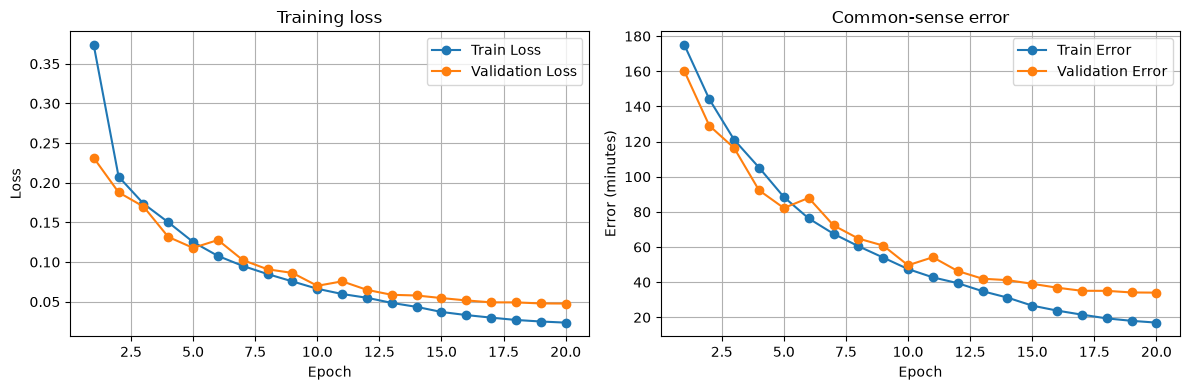


Baseline results:
Best Validation Error: 34.05 minutes (epoch 20) | Parameters: 1,437,889


In [37]:
base_params = {
    # Output formulation
    "output_type": "regression",    # "classification", "regression", "multihead" or "trig"
    "n_classes": 24,                # only for classification (must divide 720)
    "minute_mode": "class",         # only for multihead: "class" (60 classes) or "reg" (one value)
    "alpha": 1.0,                   # only for multihead: L = L_hour + alpha * L_minute
    "loss": "l1",                   # for real-valued outputs: "mse", "l1" or "smoothl1"

    # Architecture
    "cnn_channels": [32, 64, 128, 256],
    "kernel_size": 3,
    "batch_norm": True,
    "hidden_dims": [256],
    "activation": nn.ReLU,
    "dropout": 0.0,

    # Optimizer
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "weight_decay": 0.0,
    "scheduler": "cosine",          # "cosine" or None

    # Training
    "epochs": 20,
    "batch_size": 64,
    "seed": 67
}

model0, history0, val_loss0, val_err0, _, _ = run_experiment(base_params, plotting = True, verbose = True)

print("\nBaseline results:")
print(f"Best Validation Error: {val_err0:.2f} minutes (epoch {history0['best_epoch']}) | Parameters: {sum(p.numel() for p in model0.parameters()):,}")